In [392]:
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [393]:
X = torch.linspace(1, 50, 50).view(-1, 1)
X

tensor([[ 1.],
        [ 2.],
        [ 3.],
        [ 4.],
        [ 5.],
        [ 6.],
        [ 7.],
        [ 8.],
        [ 9.],
        [10.],
        [11.],
        [12.],
        [13.],
        [14.],
        [15.],
        [16.],
        [17.],
        [18.],
        [19.],
        [20.],
        [21.],
        [22.],
        [23.],
        [24.],
        [25.],
        [26.],
        [27.],
        [28.],
        [29.],
        [30.],
        [31.],
        [32.],
        [33.],
        [34.],
        [35.],
        [36.],
        [37.],
        [38.],
        [39.],
        [40.],
        [41.],
        [42.],
        [43.],
        [44.],
        [45.],
        [46.],
        [47.],
        [48.],
        [49.],
        [50.]])

In [394]:
torch.manual_seed(71)
# e = torch.randint(-8, 9, (50, 1), dtype=torch.float)
e = torch.randint(-8, 9, X.shape)
print(e)

tensor([[ 2],
        [ 7],
        [ 2],
        [ 6],
        [ 2],
        [-4],
        [ 2],
        [-5],
        [ 4],
        [ 1],
        [ 2],
        [ 3],
        [ 1],
        [-8],
        [ 5],
        [ 5],
        [-6],
        [ 0],
        [-7],
        [-8],
        [-3],
        [-1],
        [ 2],
        [-6],
        [-3],
        [ 3],
        [ 2],
        [ 3],
        [ 4],
        [ 5],
        [ 1],
        [ 7],
        [ 6],
        [-1],
        [-6],
        [-5],
        [-3],
        [ 7],
        [ 0],
        [ 8],
        [-1],
        [-2],
        [ 2],
        [-8],
        [-1],
        [ 6],
        [-8],
        [-3],
        [-7],
        [-2]])


In [395]:
y0 = 2*X + 1
y = 2*X + 1 + e

In [396]:
y.shape

torch.Size([50, 1])

In [397]:
print(type(X), type(X.numpy()))

<class 'torch.Tensor'> <class 'numpy.ndarray'>


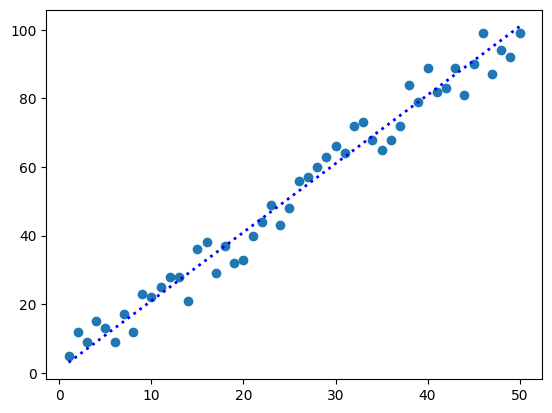

In [398]:
plt.scatter(X.numpy(), y.numpy())
plt.plot(X.numpy(), y0.numpy(), ':b', linewidth=2)

In [399]:
torch.manual_seed(59)

model = nn.Linear(1, 1)

print(model.weight, model.bias, sep='\n')

Parameter containing:
tensor([[0.1060]], requires_grad=True)
Parameter containing:
tensor([0.9638], requires_grad=True)


In [400]:
class Model(nn.Module):
    def __init__(self, in_features, out_features):

        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x):
        y_pred = self.linear(x)
        return y_pred

In [401]:
torch.manual_seed(59)

model_class = Model(1, 1)

print(model_class.linear.weight, model_class.linear.bias, sep='\n')

Parameter containing:
tensor([[0.1060]], requires_grad=True)
Parameter containing:
tensor([0.9638], requires_grad=True)


In [402]:
for name, param in model_class.named_parameters():
    print(name, '\t', np.round(param.item(), 5))

linear.weight 	 0.10598
linear.bias 	 0.9638


In [403]:
x = torch.tensor([[1], [2]], dtype=torch.float32)
print(model_class.forward(x))  # This will raise an error because the model expects input of shape (N, 1)

tensor([[1.0698],
        [1.1758]], grad_fn=<AddmmBackward0>)


In [404]:
print(model_class(x)) 

tensor([[1.0698],
        [1.1758]], grad_fn=<AddmmBackward0>)


In [405]:
x1 = np.linspace(1., 50., 50)

In [406]:
criterion = nn.MSELoss() # create loss function (criteria)

In [407]:
optimizer = torch.optim.SGD(model_class.parameters(), lr=0.001)

In [408]:
aa = model_class.parameters().__iter__()
while True:
    try:
        print(next(aa))
    except StopIteration:
        break

Parameter containing:
tensor([[0.1060]], requires_grad=True)
Parameter containing:
tensor([0.9638], requires_grad=True)


In [409]:
epochs = 50
losses = []
Weights = []
Biases = []

jumps = 5

for i in range(epochs):

    # Prediction on training data (forward pass)
    y_pred = model_class(X) # == model_class.forward(X)


    # Calculate our loss (error)
    loss = criterion(y_pred, y)

    # Record that error for plotting later
    # losses.append(loss)
    losses.append(loss.item())
    if i % jumps == 0 or i == epochs:
        Weights.append(model_class.linear.weight.item())
        Biases.append(model_class.linear.bias.item())

    print(f'Epoch {i+1}: loss = {np.round(loss.item(), 5)}, weight = {np.round(model_class.linear.weight.item(), 5)}, bias = {np.round(model_class.linear.bias.item(), 5)}')


    optimizer.zero_grad() # Reset the gradients to zero before running the backward pass for preveting gradient accumulation

    loss.backward() # Compute the gradient of the loss with respect to the parameters (weight and bias)

    optimizer.step() # Update the parameters using the gradients computed by loss.backward() and the learning rate specified in the optimizer

Epoch 1: loss = 3057.2168, weight = 0.10598, bias = 0.9638
Epoch 2: loss = 1588.53113, weight = 3.3349, bias = 1.06046
Epoch 3: loss = 830.29999, weight = 1.01483, bias = 0.99226
Epoch 4: loss = 438.85242, weight = 2.6818, bias = 1.04252
Epoch 5: loss = 236.76152, weight = 1.48402, bias = 1.00767
Epoch 6: loss = 132.42912, weight = 2.34461, bias = 1.03396
Epoch 7: loss = 78.56573, weight = 1.72623, bias = 1.01632
Epoch 8: loss = 50.75776, weight = 2.1705, bias = 1.03025
Epoch 9: loss = 36.40123, weight = 1.85125, bias = 1.0215
Epoch 10: loss = 28.98923, weight = 2.0806, bias = 1.02904
Epoch 11: loss = 25.16238, weight = 1.91577, bias = 1.02487
Epoch 12: loss = 23.18647, weight = 2.03417, bias = 1.02912
Epoch 13: loss = 22.16613, weight = 1.94906, bias = 1.02732
Epoch 14: loss = 21.63911, weight = 2.01017, bias = 1.02986
Epoch 15: loss = 21.36677, weight = 1.96622, bias = 1.02928
Epoch 16: loss = 21.22592, weight = 1.99776, bias = 1.03094
Epoch 17: loss = 21.15295, weight = 1.97506, bia

Text(0, 0.5, 'MSE Loss')

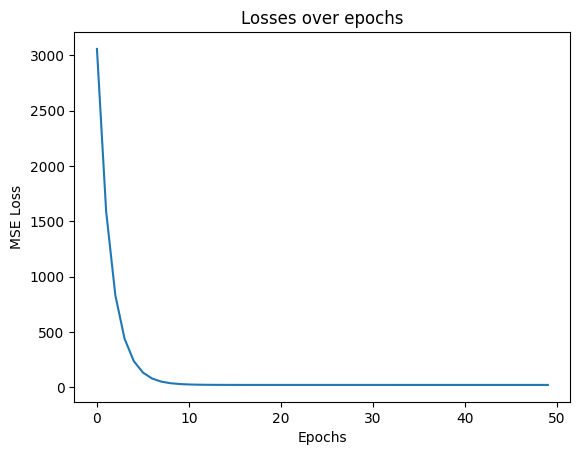

In [410]:
plt.plot(range(epochs), losses)
plt.title('Losses over epochs')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')

In [411]:
final_weight = Weights[-1]
final_bias = Biases[-1]

predicted_y = final_weight * X + final_bias

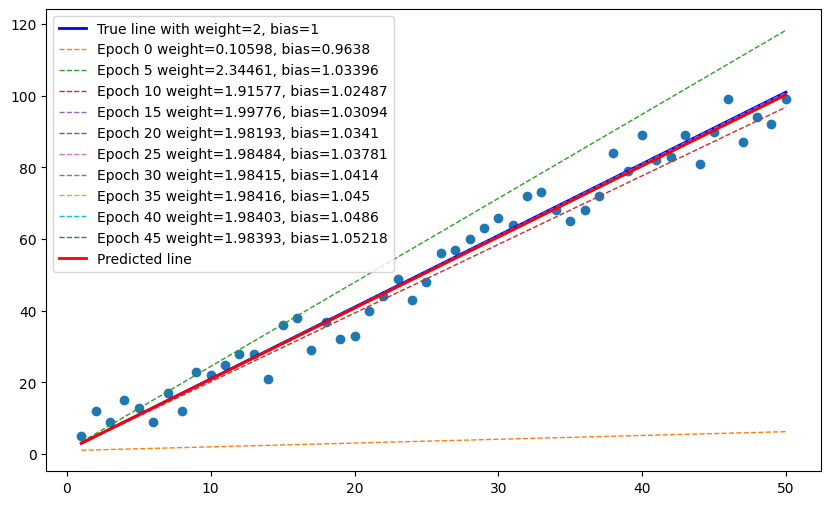

In [412]:
plt.figure(figsize=(10, 6))
plt.plot(X.numpy(), y.numpy(), 'o')
plt.plot(X.numpy(), y0.numpy(), 'b', label='True line with weight=2, bias=1', linewidth=2)
for i in range(0, len(Weights)):
    predicted = Weights[i] * X + Biases[i]
    plt.plot(X, predicted, '--', label=f'Epoch {i*jumps} weight={np.round(Weights[i], 5)}, bias={np.round(Biases[i], 5)}', linewidth=1)
plt.plot(X.numpy(), predicted_y.numpy(), 'r', label='Predicted line', linewidth=2)
plt.legend()